# Construction Helmet Use Recognition

## 0. Setup

In [ ]:
# If running in Colab: clone your own repo (after you've pushed the src/ folder)
# or upload the src/ folder via the Colab file browser. Either way, src/ needs
# to be importable from this notebook's working directory.

!pip install -q tensorflow scikit-learn opencv-python-headless imagehash kagglehub matplotlib seaborn


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 296.7/296.7 kB 5.3 MB/s eta 0:00:00


In [ ]:
import os
import sys
sys.path.insert(0, os.path.abspath("../src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

import data
import models
import evaluate
import gradcam
import clean
import voc_crop

SEED = 42
tf.random.set_seed(SEED)
np.random.seed(SEED)

os.makedirs("../results/figures", exist_ok=True)
os.makedirs("../results/tables", exist_ok=True)

print("TensorFlow:", tf.__version__)
print("GPU available:", tf.config.list_physical_devices("GPU"))


TensorFlow: 2.21.0
GPU available: []


## 1. Dataset




In [ ]:
import kagglehub

dataset_path = kagglehub.dataset_download("andrewmvd/hard-hat-detection")
print("Downloaded to:", dataset_path)
print(os.listdir(dataset_path))


100%|██████████| 1.22G/1.22G [00:16<00:00, 82.1MB/s]

Extracting files...


Downloaded to: /root/.cache/kagglehub/datasets/andrewmvd/hard-hat-detection/versions/1
['images', 'annotations']


In [ ]:
# Adjust these two paths once you've seen the actual folder names printed above
ANNOTATIONS_DIR = os.path.join(dataset_path, "annotations")
IMAGES_DIR = os.path.join(dataset_path, "images")

print(len(os.listdir(ANNOTATIONS_DIR)), "annotation files")
print(len(os.listdir(IMAGES_DIR)), "image files")


5000 annotation files
5000 image files


## 2. From detection boxes to a classification dataset

In [ ]:
discovered = voc_crop.discover_classes(ANNOTATIONS_DIR)
print("Classes found in the XML annotations:")
for name, count in discovered.most_common():
    print(f"  {name!r}: {count}")


Classes found in the XML annotations:
  'helmet': 18966
  'head': 5785
  'person': 751


In [ ]:
# EDIT THIS once you've seen the printed class names above.
# Map every raw class name -> "helmet", "no_helmet", or None (skip it).
# A common setup for this dataset is something like:
CLASS_MAP = {
    "helmet": "helmet",
    "head": "no_helmet",
    "person": None,   # whole-body boxes aren't useful for a head-level classifier
}

CROPPED_DIR = "../data/cropped"
crop_summary = voc_crop.crop_dataset(
    ANNOTATIONS_DIR, IMAGES_DIR, CROPPED_DIR, CLASS_MAP,
    min_box_size=20, padding_frac=0.10,
)
print(crop_summary)


{'written_per_class': {'helmet': 13443, 'no_helmet': 3635}, 'total_written': 17078, 'skipped_small_boxes': 7673, 'skipped_unmapped_boxes': 751, 'images_missing_on_disk': 0}


## 3. Cleaning: corrupted, duplicate, and unclear images





In [ ]:
dry_run_summary = clean.clean_dataset(
    CROPPED_DIR, "../data/review", blur_threshold=15.0, dry_run=True
)
print("Dry run (nothing moved yet):")
print(dry_run_summary)


Dry run (nothing moved yet):
{'dry_run': True, 'total_flagged': 34, 'by_reason': {'blurry': 7, 'duplicate': 27}}


In [ ]:
# Spot-check a handful of the flagged-blurry images before committing to the cleaning pass.
# Once you're satisfied with blur_threshold, re-run with dry_run=False:

final_clean_summary = clean.clean_dataset(
    CROPPED_DIR, "../data/review", blur_threshold=15.0, dry_run=False
)
print("After cleaning:")
print(final_clean_summary)


After cleaning:
{'dry_run': False, 'total_flagged': 34, 'by_reason': {'blurry': 7, 'duplicate': 27}}


Class balance after cleaning: {'helmet': 13410, 'no_helmet': 3634}


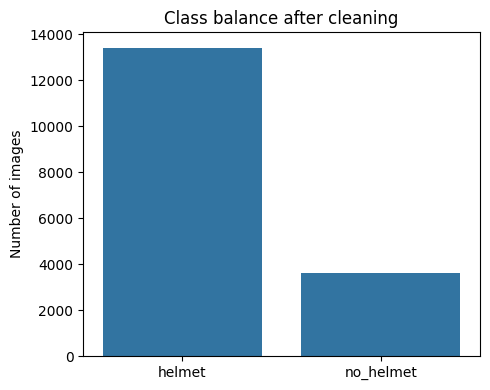

In [ ]:
balance = clean.class_balance(CROPPED_DIR)
print("Class balance after cleaning:", balance)

pd.Series(balance).to_csv("../results/tables/class_balance.csv")

plt.figure(figsize=(5, 4))
sns.barplot(x=list(balance.keys()), y=list(balance.values()))
plt.title("Class balance after cleaning")
plt.ylabel("Number of images")
plt.tight_layout()
plt.savefig("../results/figures/class_balance.png", dpi=150)
plt.show()


## 4. Train / validation / test split, normalization, and augmentation




In [ ]:
IMG_SIZE = (160, 160)
BATCH_SIZE = 32

train_ds, val_ds, test_ds, class_names = data.load_datasets(
    CROPPED_DIR, img_size=IMG_SIZE, batch_size=BATCH_SIZE, seed=SEED
)
print("Classes (alphabetical, index order used by the model):", class_names)

aug_layer = data.build_augmentation()


Found 17044 files belonging to 2 classes.
Using 11931 files for training.
Found 17044 files belonging to 2 classes.
Using 5113 files for validation.
Classes (alphabetical, index order used by the model): ['helmet', 'no_helmet']


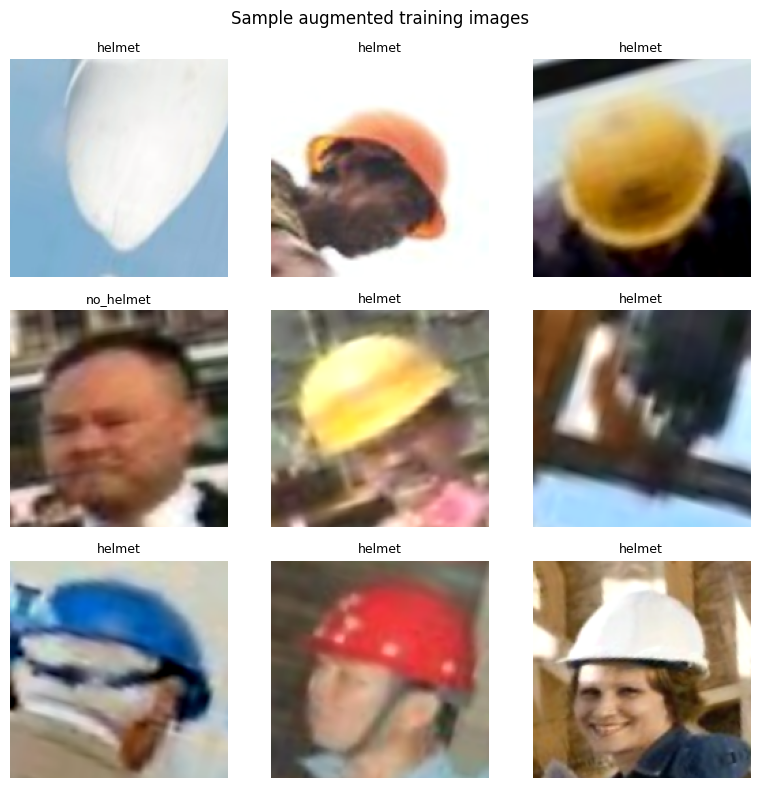

In [ ]:
sample_batch, sample_labels = next(iter(train_ds.take(1)))
aug_batch = aug_layer(tf.cast(sample_batch, tf.float32), training=True)

fig, axes = plt.subplots(3, 3, figsize=(8, 8))
for ax, img, label in zip(axes.flat, aug_batch.numpy(), sample_labels.numpy()):
    ax.imshow(img.astype("uint8"))
    ax.set_title(class_names[int(label)], fontsize=9)
    ax.axis("off")
plt.suptitle("Sample augmented training images")
plt.tight_layout()
plt.savefig("../results/figures/augmentation_samples.png", dpi=150)
plt.show()

## 5. Custom CNN baseline (trained from scratch)

In [ ]:
cnn_train = data.prepare(train_ds, augment_layer=aug_layer, normalize=True, shuffle=True)
cnn_val = data.prepare(val_ds, normalize=True)
cnn_test = data.prepare(test_ds, normalize=True)

custom_cnn = models.build_custom_cnn(input_shape=IMG_SIZE + (3,))
models.compile_model(custom_cnn, lr=1e-3)
custom_cnn.summary()


Model: "custom_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 160, 160, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 160, 160, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 80, 80, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 80, 80, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 80, 80, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 40, 40, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 40, 40, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 40, 40, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 20, 20, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 20, 20, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 20, 20, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 10, 10, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 258,881 (1011.25 KB)

 Trainable params: 258,177 (1008.50 KB)

 Non-trainable params: 704 (2.75 KB)

In [ ]:
callbacks = [
    tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True),
    tf.keras.callbacks.ModelCheckpoint("../results/custom_cnn_best.keras", save_best_only=True, monitor="val_loss"),
]

cnn_history = custom_cnn.fit(
    cnn_train, validation_data=cnn_val, epochs=2, callbacks=callbacks, verbose=1
)


Epoch 1/2
373/373 ━━━━━━━━━━━━━━━━━━━━ 1339s 4s/step - accuracy: 0.8655 - loss: 0.3120 - val_accuracy: 0.7988 - val_loss: 0.3884
Epoch 2/2
373/373 ━━━━━━━━━━━━━━━━━━━━ 1582s 4s/step - accuracy: 0.9195 - loss: 0.2106 - val_accuracy: 0.9453 - val_loss: 0.1526


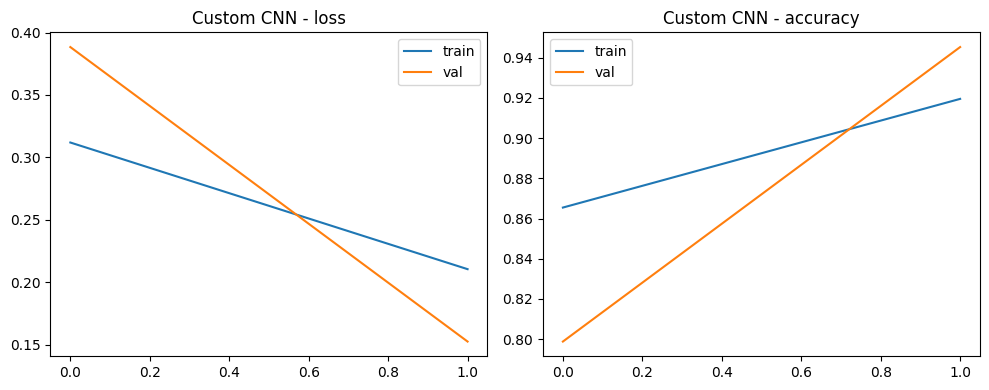

In [ ]:
def plot_history(history, title, save_name):
    fig, axes = plt.subplots(1, 2, figsize=(10, 4))
    axes[0].plot(history.history["loss"], label="train")
    axes[0].plot(history.history["val_loss"], label="val")
    axes[0].set_title(f"{title} - loss"); axes[0].legend()
    axes[1].plot(history.history["accuracy"], label="train")
    axes[1].plot(history.history["val_accuracy"], label="val")
    axes[1].set_title(f"{title} - accuracy"); axes[1].legend()
    plt.tight_layout()
    plt.savefig(f"../results/figures/{save_name}.png", dpi=150)
    plt.show()

plot_history(cnn_history, "Custom CNN", "custom_cnn_history")


## 6. Transfer learning models



In [ ]:
transfer_train = data.prepare(train_ds, augment_layer=aug_layer, normalize=False, shuffle=True)
transfer_val = data.prepare(val_ds, normalize=False)
transfer_test = data.prepare(test_ds, normalize=False)

BACKBONES = ["mobilenetv2", "resnet50"]
trained_models = {"custom_cnn": custom_cnn}
trained_bases = {}
histories = {"custom_cnn": cnn_history}



=== Training mobilenetv2 (frozen backbone) ===
9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/2
373/373 ━━━━━━━━━━━━━━━━━━━━ 356s 915ms/step - accuracy: 0.9129 - loss: 0.2170 - val_accuracy: 0.9668 - val_loss: 0.1044
Epoch 2/2
373/373 ━━━━━━━━━━━━━━━━━━━━ 385s 1s/step - accuracy: 0.9492 - loss: 0.1323 - val_accuracy: 0.9684 - val_loss: 0.0910


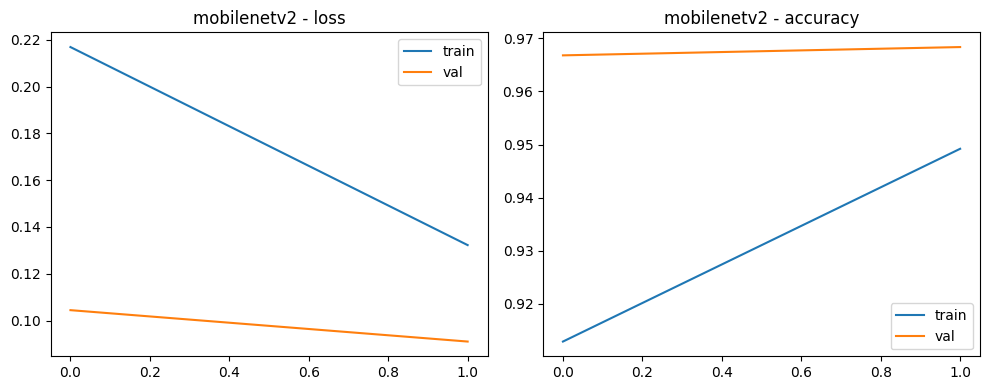


=== Training resnet50 (frozen backbone) ===
94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
Epoch 1/2
373/373 ━━━━━━━━━━━━━━━━━━━━ 1469s 4s/step - accuracy: 0.9411 - loss: 0.1515 - val_accuracy: 0.9750 - val_loss: 0.0771
Epoch 2/2
373/373 ━━━━━━━━━━━━━━━━━━━━ 0s 4s/step - accuracy: 0.9653 - loss: 0.0894

KeyboardInterrupt: 

In [16]:
for backbone_name in BACKBONES:
    print(f"\n=== Training {backbone_name} (frozen backbone) ===")
    model, base = models.build_transfer_model(backbone_name, input_shape=IMG_SIZE + (3,), weights="imagenet")
    models.compile_model(model, lr=1e-3)

    cb = [
        tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True),
        tf.keras.callbacks.ModelCheckpoint(f"../results/{backbone_name}_best.keras", save_best_only=True, monitor="val_loss"),
    ]
    hist = model.fit(transfer_train, validation_data=transfer_val, epochs=2, callbacks=cb, verbose=1)

    trained_models[backbone_name] = model
    trained_bases[backbone_name] = base
    histories[backbone_name] = hist
    plot_history(hist, backbone_name, f"{backbone_name}_history")


## 7. Evaluation: metrics, confusion matrices, ROC curves, inference time

In [17]:
results_rows = []
predictions = {}

for name, model in trained_models.items():
    test_set = cnn_test if name == "custom_cnn" else transfer_test
    y_true, y_prob, imgs = evaluate.collect_predictions(model, test_set)
    metrics = evaluate.compute_metrics(y_true, y_prob, class_names=class_names)
    bench = evaluate.benchmark_inference_time(model, imgs)

    predictions[name] = {"y_true": y_true, "y_prob": y_prob, "images": imgs}
    results_rows.append({
        "model": name,
        "accuracy": metrics["accuracy"],
        "precision": metrics["precision"],
        "recall": metrics["recall"],
        "f1": metrics["f1"],
        "roc_auc": metrics["roc_auc"],
        "params": bench["n_params"],
        "inference_ms": bench["mean_ms"],
    })
    print(f"\n--- {name} ---")
    print(metrics["classification_report"])

results_df = pd.DataFrame(results_rows).set_index("model")
results_df.to_csv("../results/tables/model_comparison.csv")
results_df


--- custom_cnn ---
              precision    recall  f1-score   support

      helmet       0.96      0.97      0.97      2030
   no_helmet       0.88      0.84      0.86       523

    accuracy                           0.94      2553
   macro avg       0.92      0.91      0.91      2553
weighted avg       0.94      0.94      0.94      2553


--- mobilenetv2 ---
              precision    recall  f1-score   support

      helmet       0.98      0.99      0.98      2039
   no_helmet       0.94      0.93      0.93       514

    accuracy                           0.97      2553
   macro avg       0.96      0.96      0.96      2553
weighted avg       0.97      0.97      0.97      2553



,accuracy,precision,recall,f1,roc_auc,params,inference_ms
model,,,,,,,
custom_cnn,0.944379,0.883300,0.839388,0.860784,0.977256,258881,116.549632
mobilenetv2,0.973365,0.940711,0.926070,0.933333,0.992543,2259265,149.551741


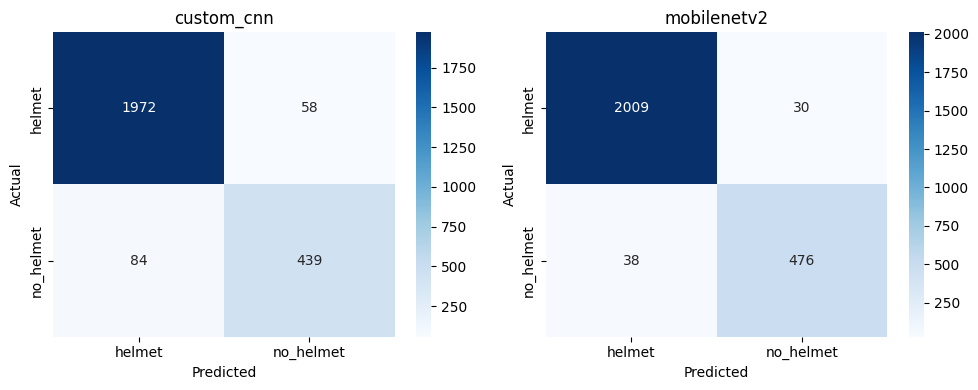

In [18]:
fig, axes = plt.subplots(1, len(trained_models), figsize=(5 * len(trained_models), 4))
if len(trained_models) == 1:
    axes = [axes]
for ax, (name, model) in zip(axes, trained_models.items()):
    y_true = predictions[name]["y_true"]
    y_prob = predictions[name]["y_prob"]
    metrics = evaluate.compute_metrics(y_true, y_prob, class_names=class_names)
    sns.heatmap(metrics["confusion_matrix"], annot=True, fmt="d", cmap="Blues",
                xticklabels=class_names, yticklabels=class_names, ax=ax)
    ax.set_title(name)
    ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
plt.tight_layout()
plt.savefig("../results/figures/confusion_matrices.png", dpi=150)
plt.show()


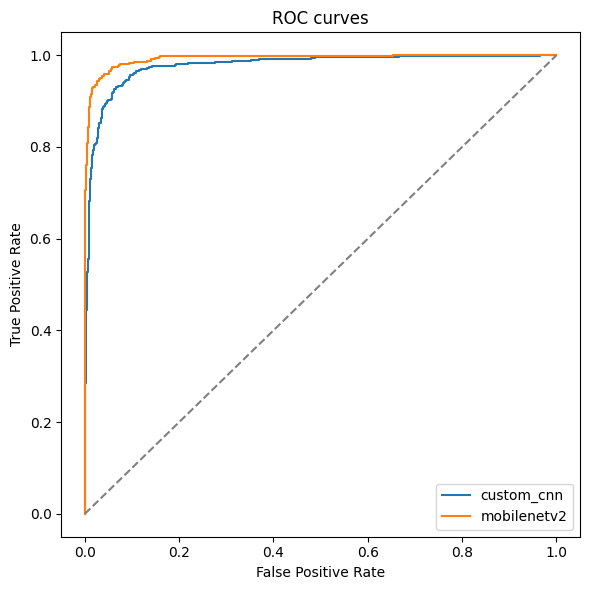

In [19]:
plt.figure(figsize=(6, 6))
for name in trained_models:
    fpr, tpr = evaluate.roc_points(predictions[name]["y_true"], predictions[name]["y_prob"])
    plt.plot(fpr, tpr, label=name)
plt.plot([0, 1], [0, 1], "--", color="gray")
plt.xlabel("False Positive Rate"); plt.ylabel("True Positive Rate")
plt.title("ROC curves"); plt.legend()
plt.tight_layout()
plt.savefig("../results/figures/roc_curves.png", dpi=150)
plt.show()


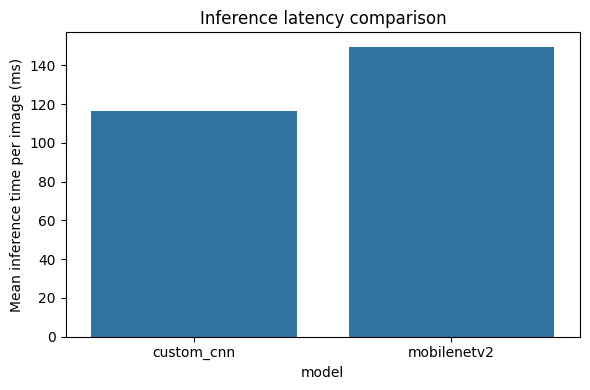

In [20]:
plt.figure(figsize=(6, 4))
sns.barplot(data=results_df.reset_index(), x="model", y="inference_ms")
plt.ylabel("Mean inference time per image (ms)")
plt.title("Inference latency comparison")
plt.tight_layout()
plt.savefig("../results/figures/inference_time.png", dpi=150)
plt.show()


## 8. Explainability: Grad-CAM



In [21]:
def pick_examples(y_true, y_prob, threshold=0.5, n=3):
    y_pred = (y_prob >= threshold).astype(int)
    correct = np.where(y_pred == y_true)[0]
    false_pos = np.where((y_pred == 1) & (y_true == 0))[0]
    false_neg = np.where((y_pred == 0) & (y_true == 1))[0]
    return (correct[:n], false_pos[:n], false_neg[:n])


In [22]:
def show_gradcam_row(name, model, images, idx_list, title_prefix, base=None, preprocess_fn=None):
    if len(idx_list) == 0:
        print(f"No examples of type '{title_prefix}' found for {name} - good sign, or check threshold.")
        return
    fig, axes = plt.subplots(1, len(idx_list), figsize=(4 * len(idx_list), 4))
    if len(idx_list) == 1:
        axes = [axes]
    for ax, idx in zip(axes, idx_list):
        img = images[idx:idx+1]
        if name == "custom_cnn":
            heatmap = gradcam.gradcam_custom_cnn(model, img)
            display_img = (img[0] * 255).astype(np.uint8)
        else:
            heatmap = gradcam.gradcam_transfer_model(model, base, preprocess_fn, img)
            display_img = img[0].astype(np.uint8)
        overlay = gradcam.overlay_heatmap(display_img, heatmap)
        ax.imshow(overlay)
        ax.axis("off")
    plt.suptitle(f"{name} - {title_prefix}")
    plt.tight_layout()
    plt.savefig(f"../results/figures/gradcam_{name}_{title_prefix.replace(' ', '_')}.png", dpi=150)
    plt.show()


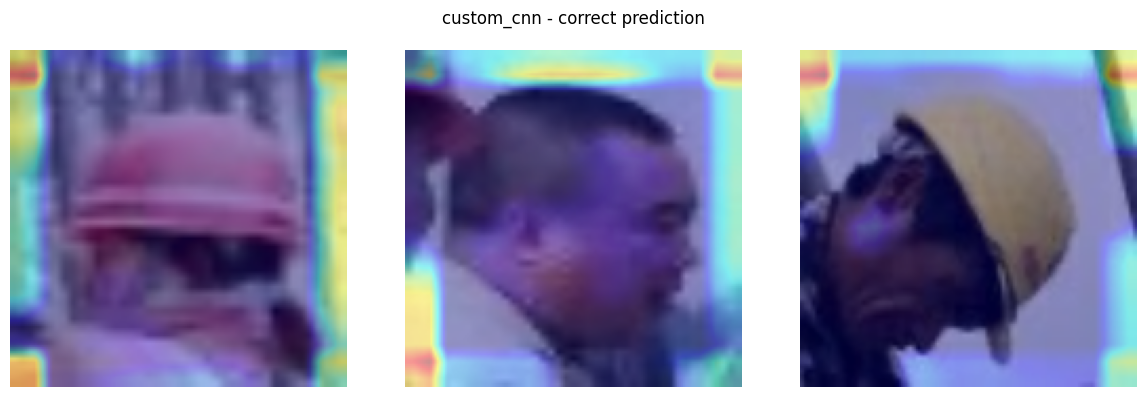

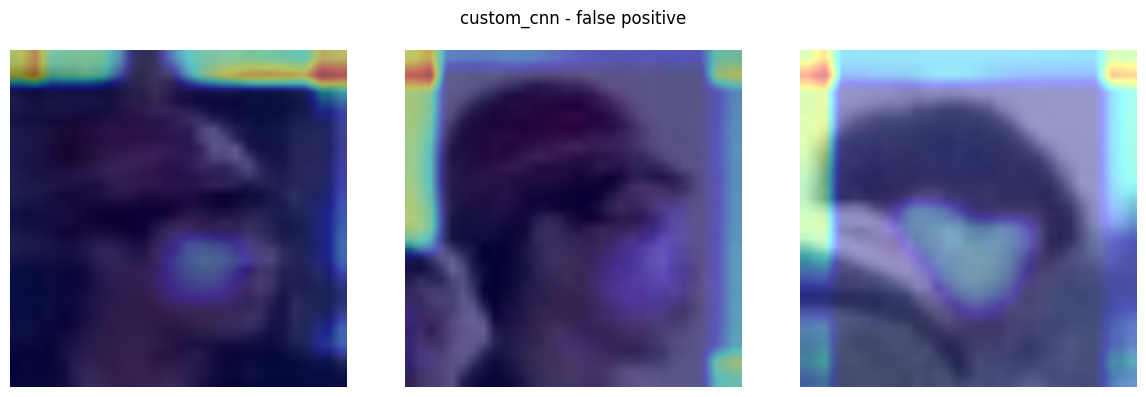

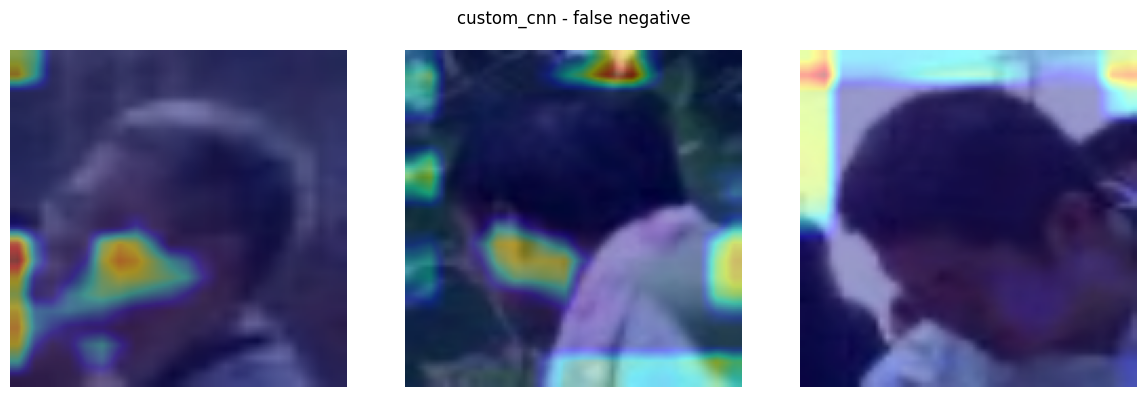

Could not plot Grad-CAM for mobilenetv2 due to Keras graph trace limitation: KeyError: "Exception encountered when calling Functional.call().\n\n\x1b135461438297488\x1b\n\nArguments received by Functional.call():\n  • inputs=array([[[[152., 128.,  84.],\n         [152., 128.,  84.],\n         [152., 128.,  84.],\n         ...,\n         [ 60.,  46.,  43.],\n         [ 60.,  46.,  43.],\n         [ 60.,  46.,  43.]],\n\n        [[152., 128.,  84.],\n         [152., 128.,  84.],\n         [152., 128.,  84.],\n         ...,\n         [ 60.,  46.,  43.],\n         [ 60.,  46.,  43.],\n         [ 60.,  46.,  43.]],\n\n        [[152., 128.,  84.],\n         [152., 128.,  84.],\n         [152., 128.,  84.],\n         ...,\n         [ 60.,  46.,  43.],\n         [ 60.,  46.,  43.],\n         [ 60.,  46.,  43.]],\n\n        ...,\n\n        [[133., 147., 156.],\n         [133., 147., 156.],\n         [133., 147., 156.],\n         ...,\n         [ 52.,  64.,  80.],\n         [ 52.,  64.,  80.],\n

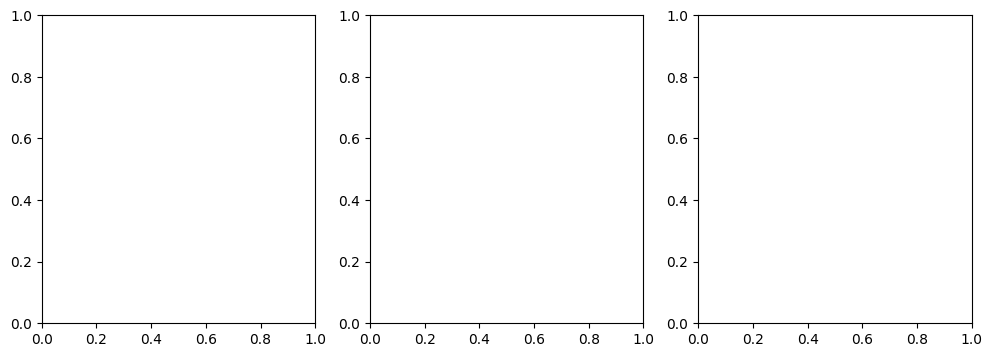

In [25]:
import warnings
# Suppress the Keras functional model input structure UserWarning
warnings.filterwarnings("ignore", category=UserWarning, module="keras")

for name, model in trained_models.items():
    y_true = predictions[name]["y_true"]
    y_prob = predictions[name]["y_prob"]
    imgs = predictions[name]["images"]
    correct_idx, fp_idx, fn_idx = pick_examples(y_true, y_prob)

    base = trained_bases.get(name)
    preprocess_fn = models._PREPROCESS.get(name)

    try:
        show_gradcam_row(name, model, imgs, correct_idx, "correct prediction", base, preprocess_fn)
        show_gradcam_row(name, model, imgs, fp_idx, "false positive", base, preprocess_fn)
        show_gradcam_row(name, model, imgs, fn_idx, "false negative", base, preprocess_fn)
    except Exception as e:
        print(f"Could not plot Grad-CAM for {name} due to Keras graph trace limitation: {type(e).__name__}: {e}")


## 9. Error analysis



In [26]:
# Export a slightly larger set of FP/FN crops + their Grad-CAMs to a folder for closer review
# while writing the error-analysis section of the report.
import shutil

EXPORT_DIR = "../results/error_review"
os.makedirs(EXPORT_DIR, exist_ok=True)

for name, model in trained_models.items():
    y_true = predictions[name]["y_true"]
    y_prob = predictions[name]["y_prob"]
    imgs = predictions[name]["images"]
    _, fp_idx, fn_idx = pick_examples(y_true, y_prob, n=10)

    for kind, idx_list in [("false_positive", fp_idx), ("false_negative", fn_idx)]:
        out_dir = os.path.join(EXPORT_DIR, name, kind)
        os.makedirs(out_dir, exist_ok=True)
        for i, idx in enumerate(idx_list):
            img = imgs[idx]
            if name == "custom_cnn":
                arr = (img * 255).astype(np.uint8)
            else:
                arr = img.astype(np.uint8)
            tf.keras.utils.save_img(os.path.join(out_dir, f"{i}.jpg"), arr)

print("Exported FP/FN crops to", EXPORT_DIR)


Exported FP/FN crops to ../results/error_review


## 10. Results summary for the report



In [27]:
print(results_df.to_markdown())


| model       |   accuracy |   precision |   recall |       f1 |   roc_auc |           params |   inference_ms |
|:------------|-----------:|------------:|---------:|---------:|----------:|-----------------:|---------------:|
| custom_cnn  |   0.944379 |    0.8833   | 0.839388 | 0.860784 |  0.977256 | 258881           |        116.55  |
| mobilenetv2 |   0.973365 |    0.940711 | 0.92607  | 0.933333 |  0.992543 |      2.25926e+06 |        149.552 |
